In [166]:
import pandas as pd
import glob, os
from tqdm.notebook import tqdm
import json
import plotly.express as px
import plotly.graph_objects as go
import geopandas as gpd
import numpy as np
import chart_studio
import chart_studio.plotly as py
import plotly.io as pio
import re, string, unicodedata
import nltk
from bs4 import BeautifulSoup
from nltk import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import LancasterStemmer, WordNetLemmatizer
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt


pd.set_option('display.max_columns', None)

In [155]:
username = 'politicai' # your username
api_key = 'REDACTED' # your api key - go to profile > settings > regenerate key
chart_studio.tools.set_credentials_file(username=username, api_key=api_key)
# py.plot(fig_object, filename = 'gdp_per_cap', auto_open=True)
# pio.write_html(fig, file=’index.html’, auto_open=True)

In [199]:
class cleantext():
    
    def __init__(self, text = "test"):
        self.text = text
        self.banned_words = ["lectura", "fácil"]
        
    def strip_html(self):
        soup = BeautifulSoup(self.text, "html.parser")
        self.text = soup.get_text()
        return self

    def remove_between_square_brackets(self):
        self.text = re.sub('\[[^]]*\]', '', self.text)
        return self

    def remove_numbers(self):
        self.text = re.sub('[-+]?[0-9]+', '', self.text)
        return self
    
    def get_words(self):
        self.words = nltk.word_tokenize(self.text)
        return self

    def to_lowercase(self):
        """Convert all characters to lowercase from list of tokenized words"""
        new_words = []
        for word in self.words:
            new_word = word.lower()
            new_words.append(new_word)
        self.words = new_words
        return self

    def remove_punctuation(self):
        """Remove punctuation from list of tokenized words"""
        new_words = []
        for word in self.words:
            new_word = re.sub(r'[^\w\s]', '', word)
            if new_word != '':
                new_words.append(new_word)
        self.words = new_words
        return self

    def remove_stopwords(self):
        """Remove stop words from list of tokenized words"""
        new_words = []
        for word in self.words:
            if word not in stopwords.words('spanish'):
                new_words.append(word)
        self.words = new_words
        return self

    def remove_customwords(self):
        """Remove stop words from list of tokenized words"""
        new_words = []
        for word in self.words:
            if word not in self.banned_words:
                new_words.append(word)
        self.words = new_words
        return self

    def stem_words(self):
        """Stem words in list of tokenized words"""
        stemmer = LancasterStemmer()
        stems = []
        for word in self.words:
            stem = stemmer.stem(word)
            stems.append(stem)
        self.words = stems
        return self

    def lemmatize_verbs(self):
        """Lemmatize verbs in list of tokenized words"""
        lemmatizer = WordNetLemmatizer()
        lemmas = []
        for word in self.words:
            lemma = lemmatizer.lemmatize(word, pos='v')
            lemmas.append(lemma)
        self.words = lemmas
        return self
    
    def join_words(self):
        self.words = ' '.join(self.words)
        return self
    
    def do_all(self, text):
        
        self.text = text
        self = self.strip_html()
        self = self.remove_between_square_brackets()
        self = self.remove_numbers()        
        self = self.get_words()
        self = self.to_lowercase()
        self = self.remove_punctuation()
        self = self.remove_stopwords()
        self = self.remove_customwords()        
#        self = self.stem_words()
#        self = self.lemmatize_verbs()
        self = self.join_words()
        
        return self.words
    
# Define a function to plot word cloud
def plot_cloud(wordcloud):
    # Set figure size
    plt.figure(figsize=(40, 30))
    # Display image
    plt.imshow(wordcloud) 
    # No axis details
    plt.axis("off")
    
def wordListToFreqDict(wordlist):
    wordfreq = [wordlist.count(p) for p in wordlist]
    return dict(list(zip(wordlist,wordfreq)))

In [200]:
"""import nltk
import ssl

try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

nltk.download()"""

'import nltk\nimport ssl\n\ntry:\n    _create_unverified_https_context = ssl._create_unverified_context\nexcept AttributeError:\n    pass\nelse:\n    ssl._create_default_https_context = _create_unverified_https_context\n\nnltk.download()'

# Procesar PDFs

In [201]:
txt_ciudadanos = open("../../data/staging/programas_electorales/201910/ciudadanos.txt", "r").read()
txt_podemos = open("../../data/staging/programas_electorales/201910/podemos.txt", "r").read()
txt_psoe = open("../../data/staging/programas_electorales/201910/psoe.txt", "r").read()
txt_mas_pais = open("../../data/staging/programas_electorales/201910/mas_pais.txt", "r").read()
txt_pp = open("../../data/staging/programas_electorales/201910/pp.txt", "r").read()
txt_vox = open("../../data/staging/programas_electorales/201910/vox.txt", "r").read()

In [202]:
ct = cleantext()

In [203]:
str_ciudadanos = ct.do_all(txt_ciudadanos)
str_podemos = ct.do_all(txt_podemos)
str_psoe = ct.do_all(txt_psoe)
str_mas_pais = ct.do_all(txt_mas_pais)
str_pp = ct.do_all(txt_pp)
str_vox = ct.do_all(txt_vox)

In [204]:
freq_ciudadanos = wordListToFreqDict(str_ciudadanos.split(" "))
freq_podemos = wordListToFreqDict(str_podemos.split(" "))
freq_psoe = wordListToFreqDict(str_psoe.split(" "))
freq_mas_pais = wordListToFreqDict(str_mas_pais.split(" "))
freq_pp = wordListToFreqDict(str_pp.split(" "))
freq_vox = wordListToFreqDict(str_vox.split(" "))

# Wordclouds

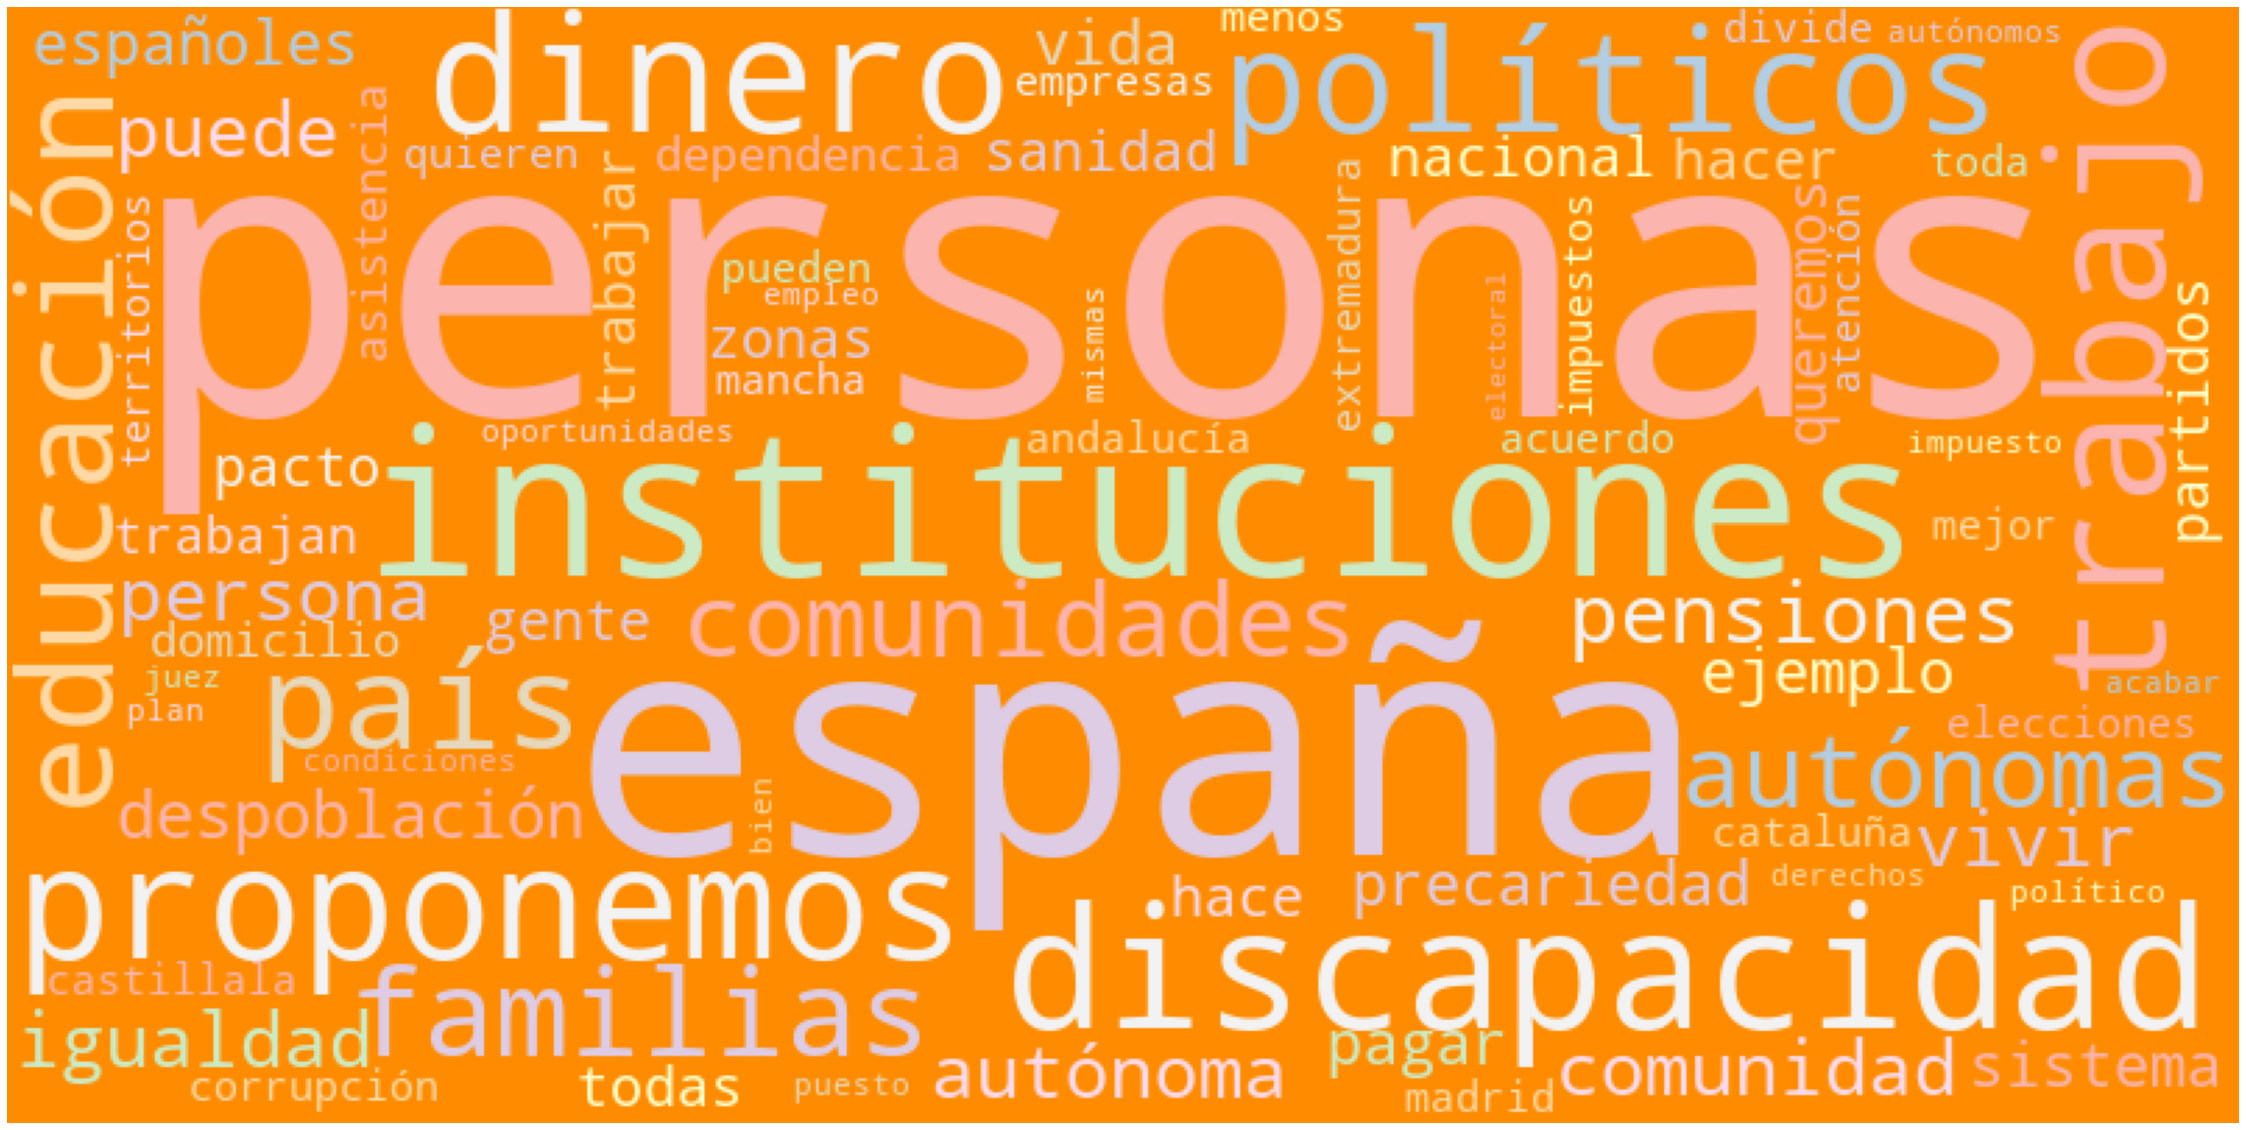

In [217]:
# Ciudadanos
wordcloud = WordCloud(width = 800, height = 400, random_state=1, background_color='darkorange', max_words=75, 
                      colormap='Pastel1', ranks_only=True, collocations=True, stopwords = STOPWORDS, 
                      normalize_plurals=True, min_word_length=3).generate_from_frequencies(freq_ciudadanos)
# Plot
plot_cloud(wordcloud)

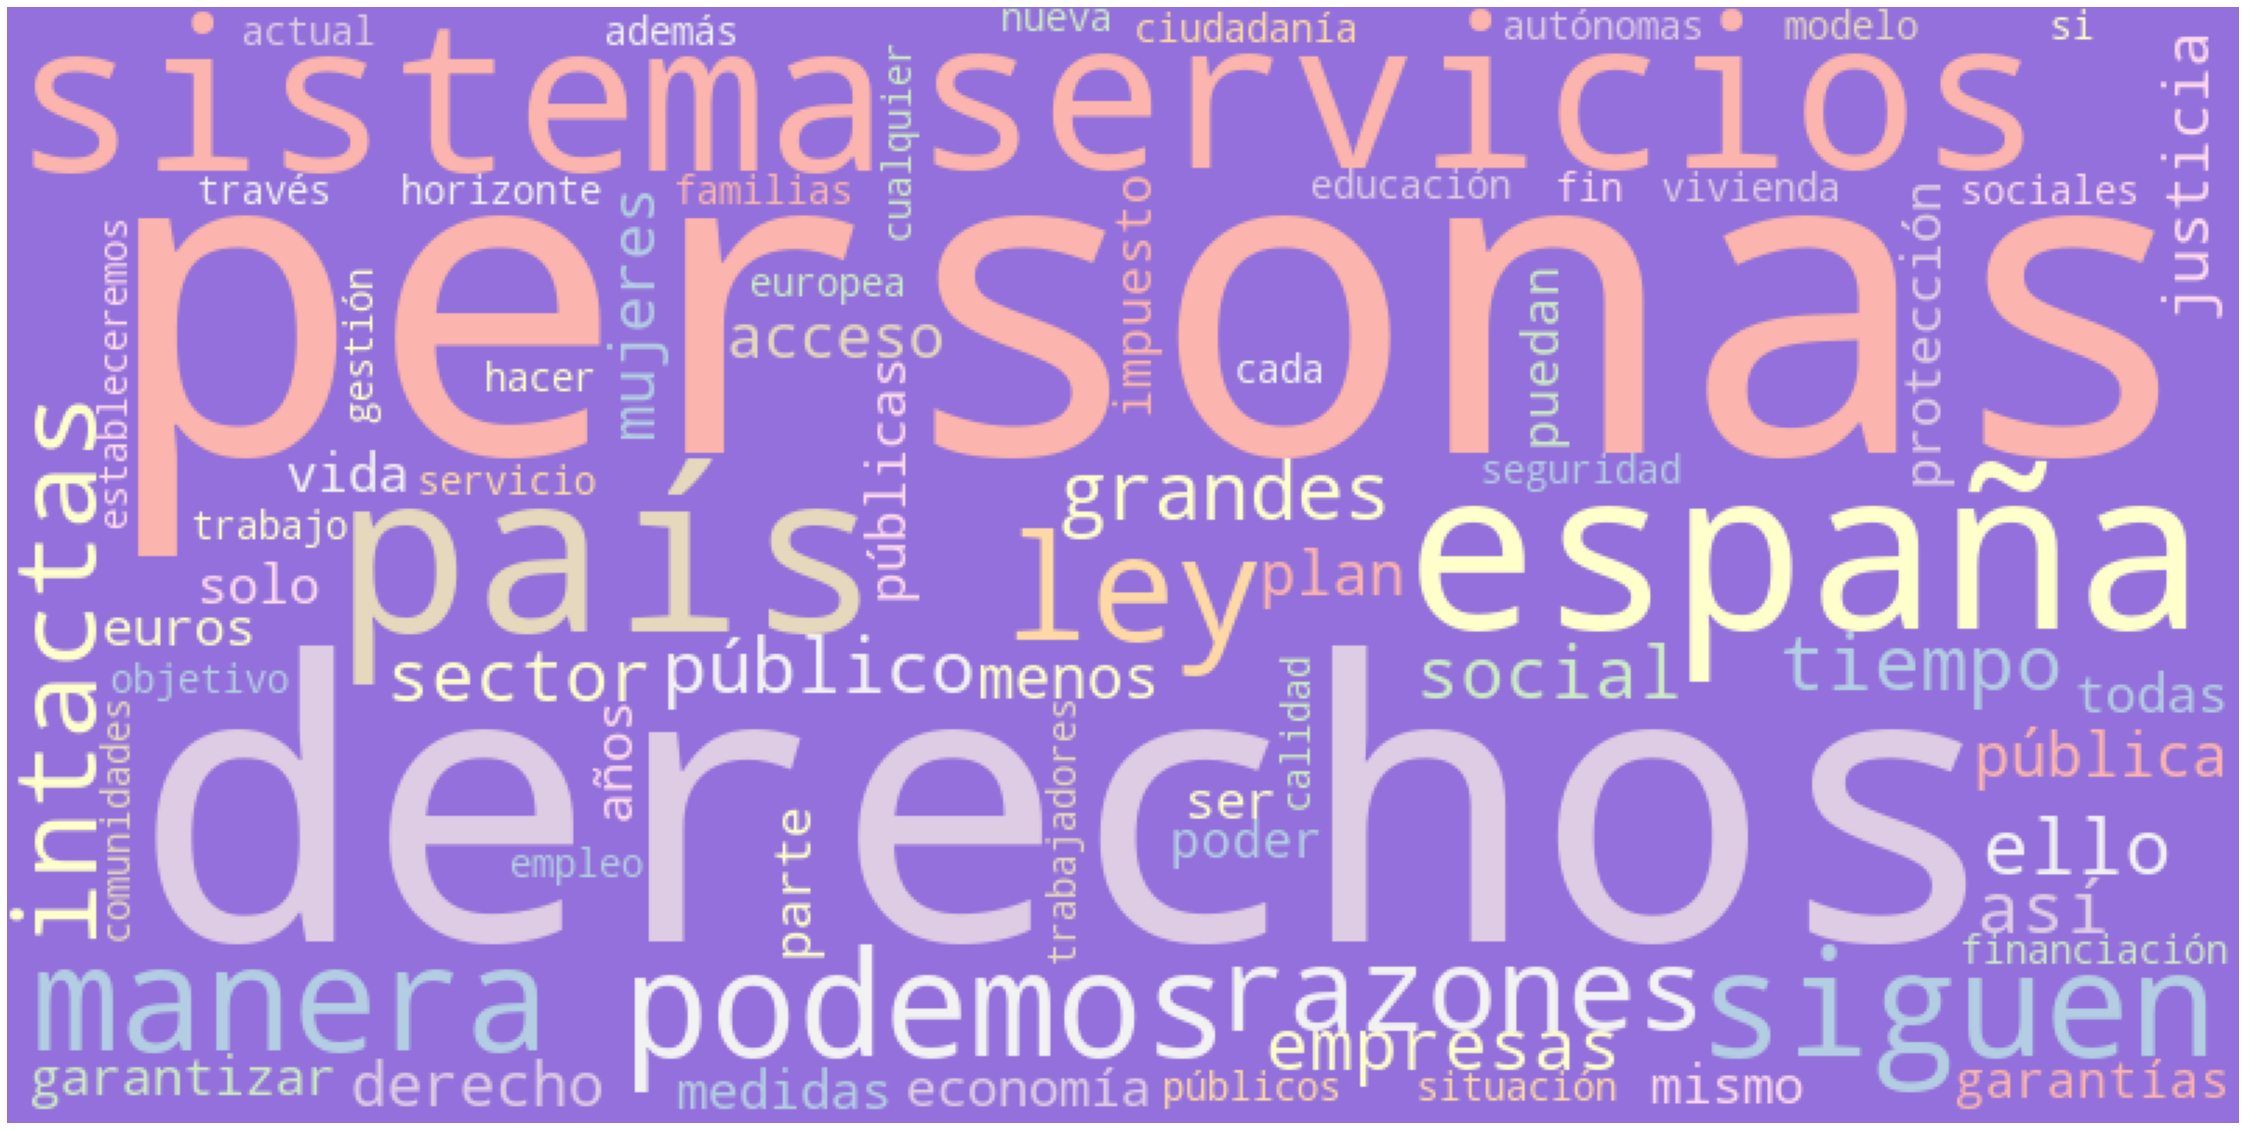

In [221]:
# Podemos
wordcloud = WordCloud(width = 800, height = 400, random_state=1, background_color='mediumpurple', max_words=75, 
                      colormap='Pastel1', ranks_only=True, collocations=True, stopwords = STOPWORDS, 
                      normalize_plurals=True, min_word_length=3).generate_from_frequencies(freq_podemos)
# Plot
plot_cloud(wordcloud)

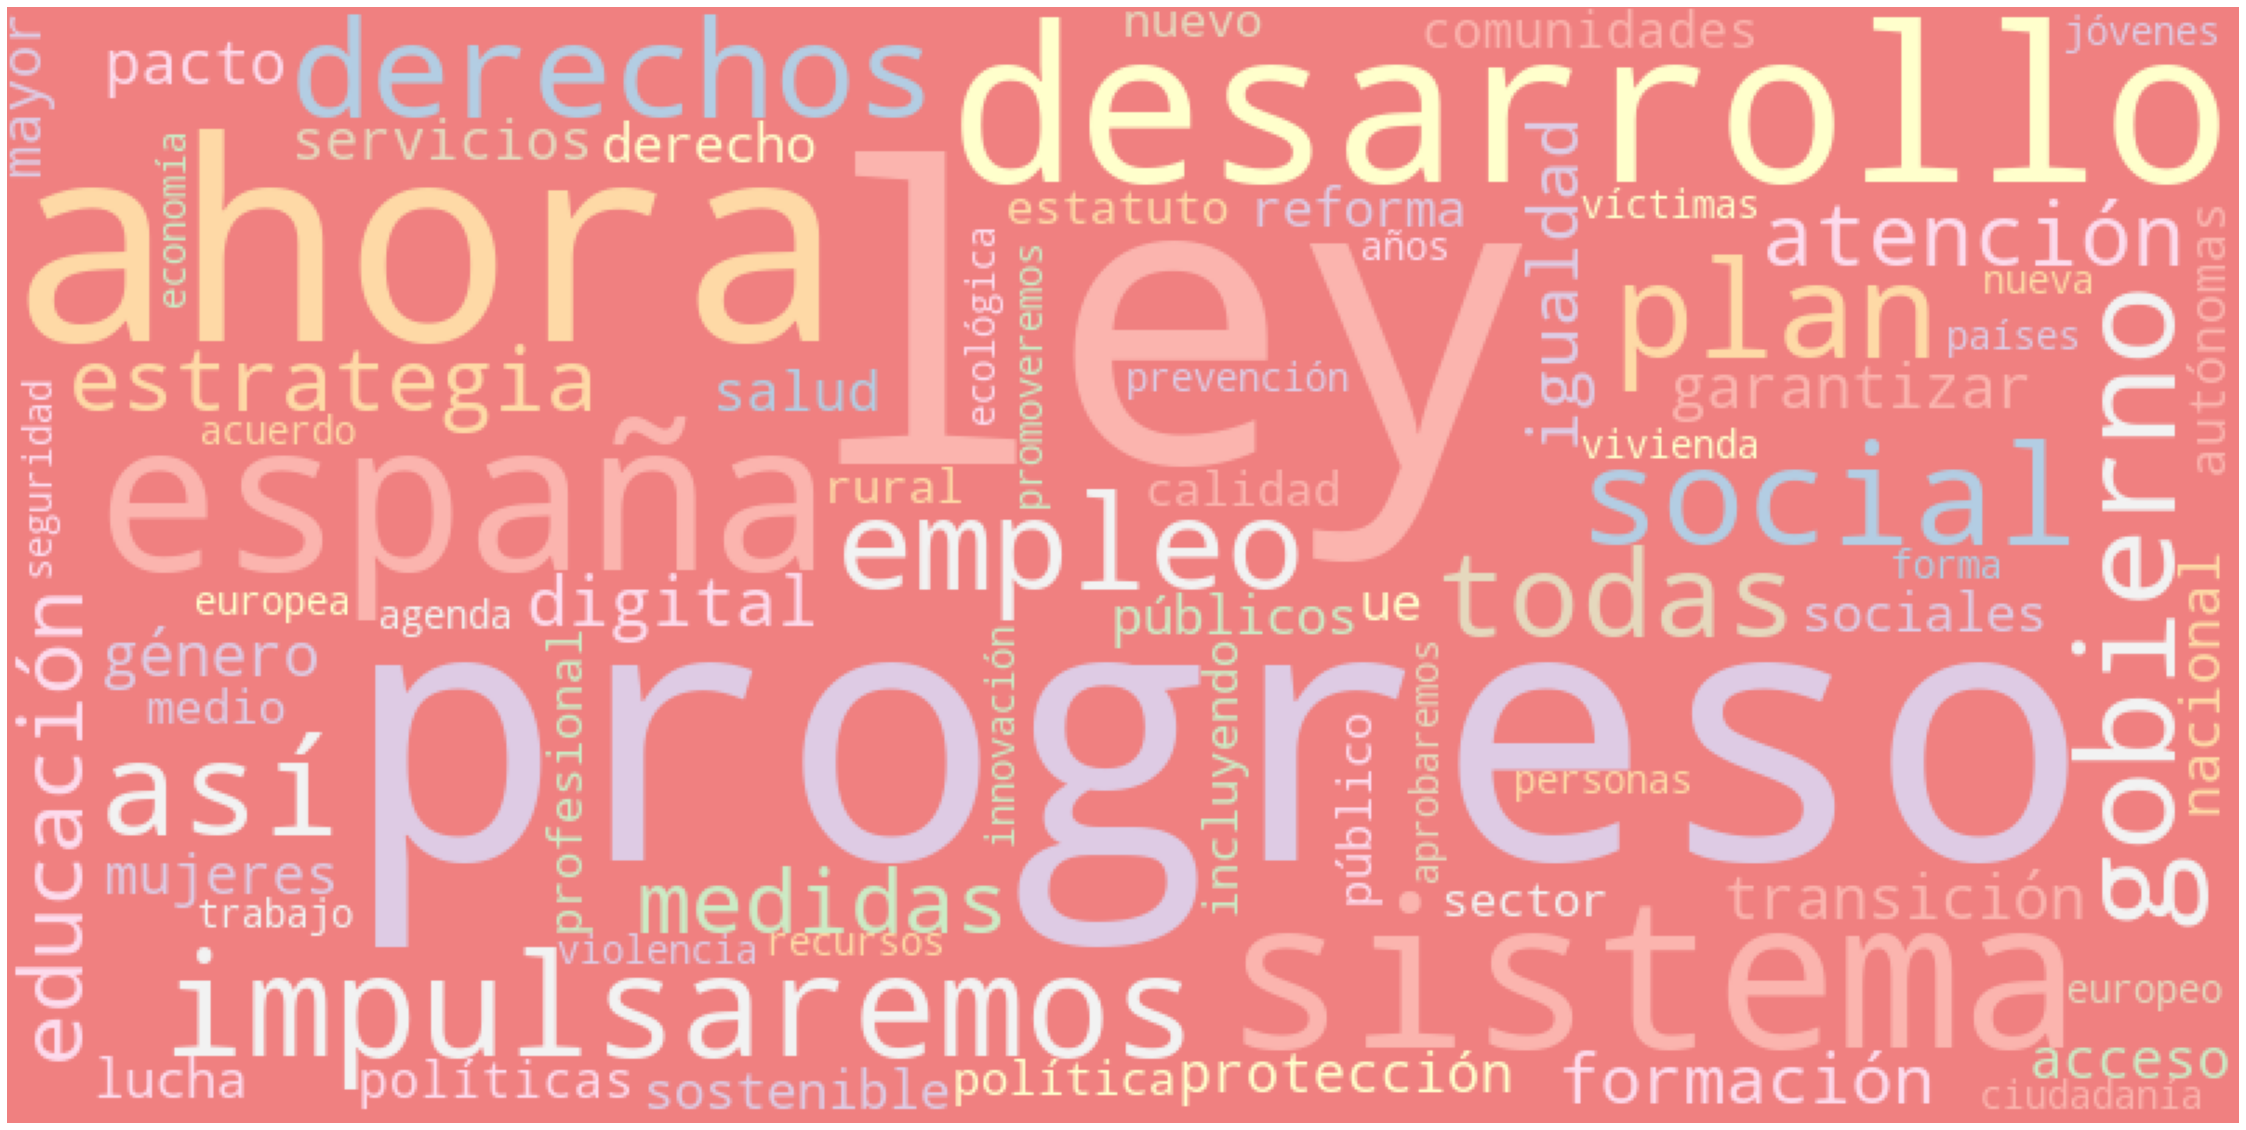

In [224]:
# PSOE
wordcloud = WordCloud(width = 800, height = 400, random_state=1, background_color='lightcoral', max_words=75, 
                      colormap='Pastel1', ranks_only=True, collocations=True, stopwords = STOPWORDS, 
                      normalize_plurals=True, min_word_length=3).generate_from_frequencies(freq_psoe)
# Plot
plot_cloud(wordcloud)

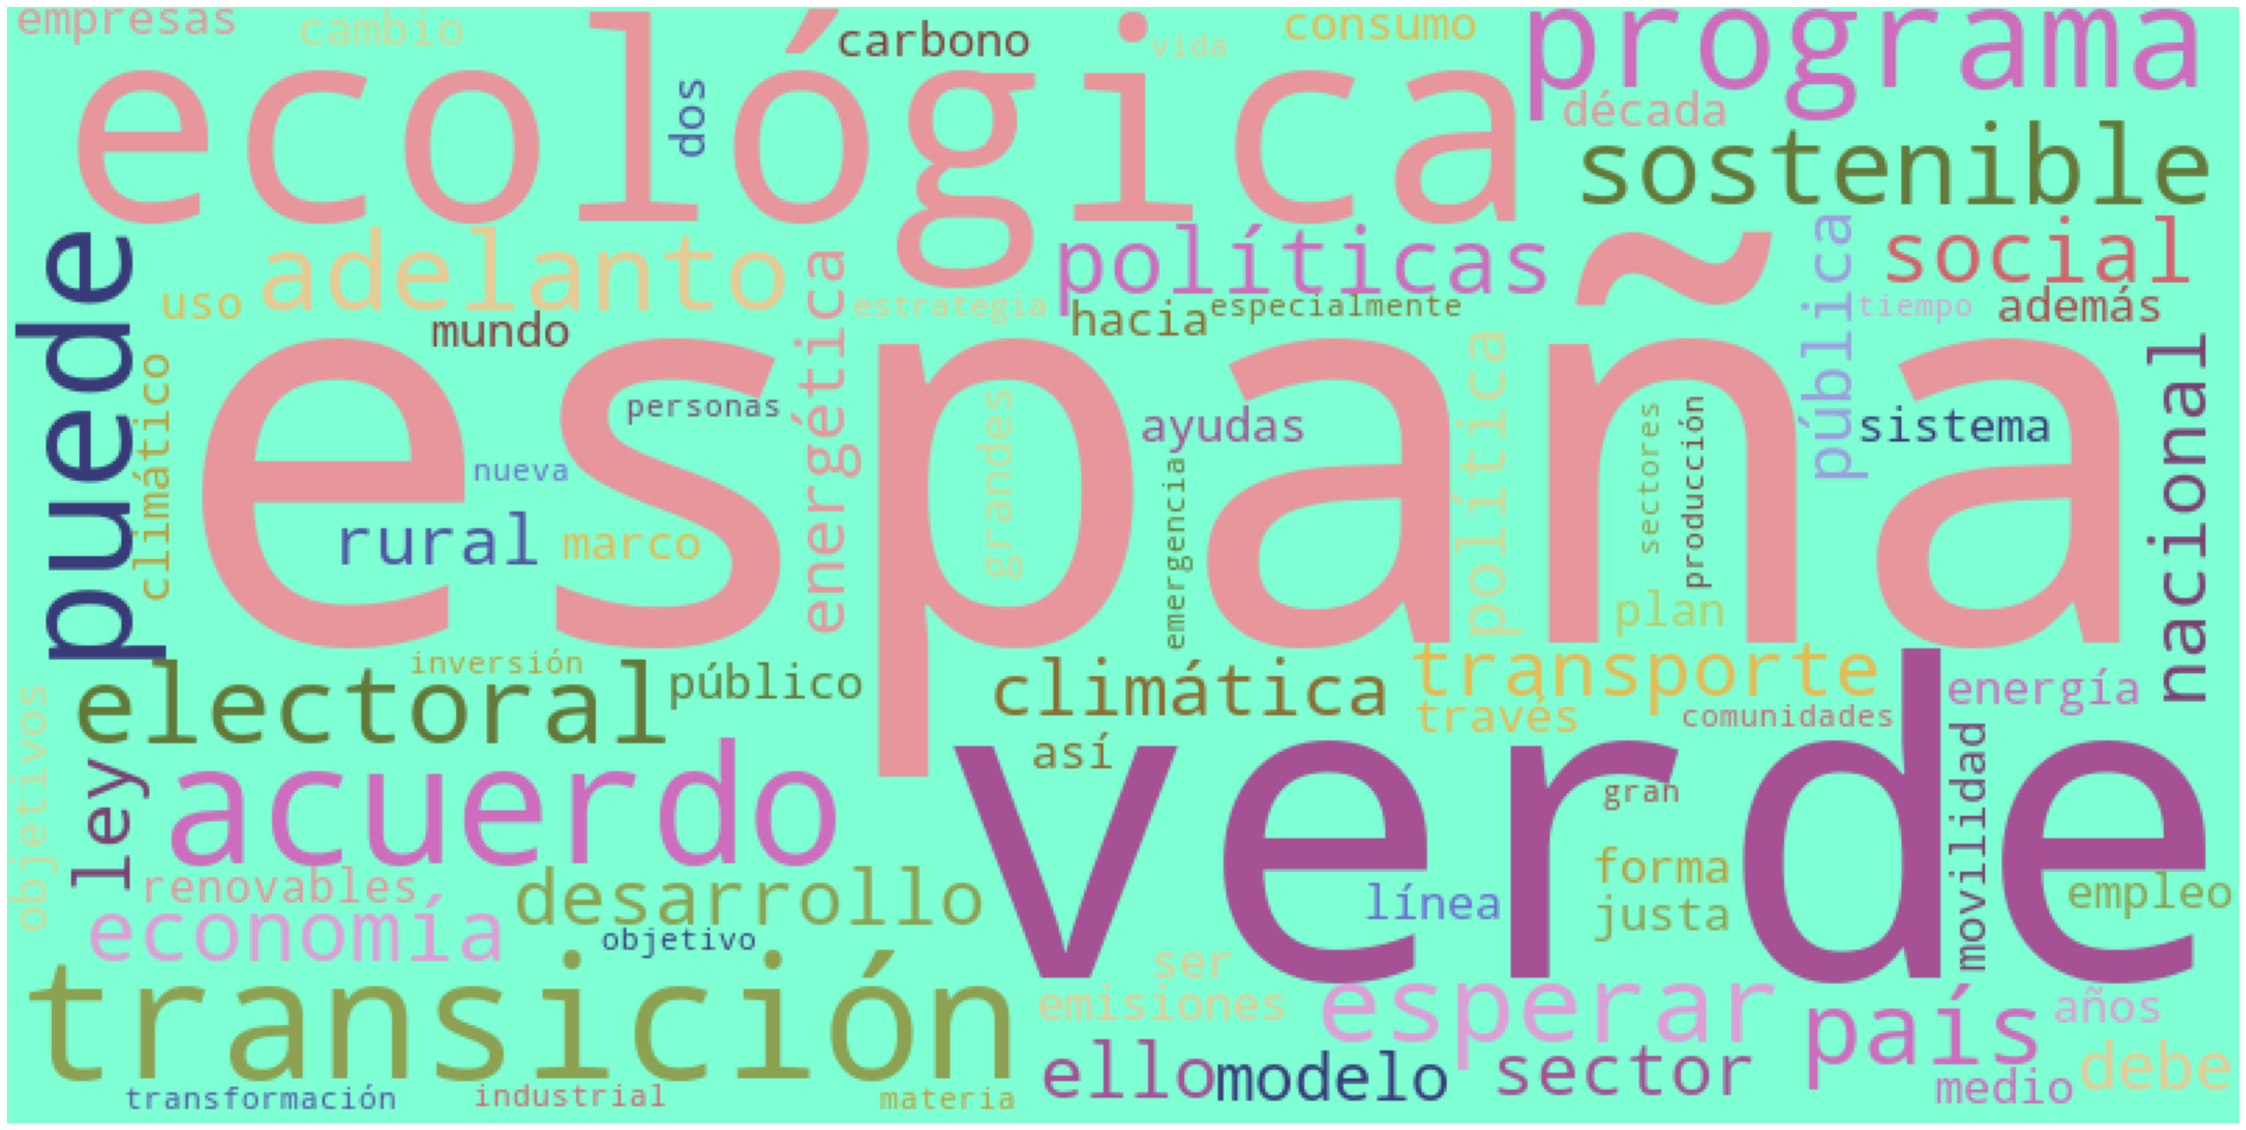

In [231]:
# Más País
wordcloud = WordCloud(width = 800, height = 400, random_state=1, background_color='aquamarine', max_words=75, 
                      colormap='tab20b', ranks_only=True, collocations=True, stopwords = STOPWORDS, 
                      normalize_plurals=True, min_word_length=3).generate_from_frequencies(freq_mas_pais)
# Plot
plot_cloud(wordcloud)

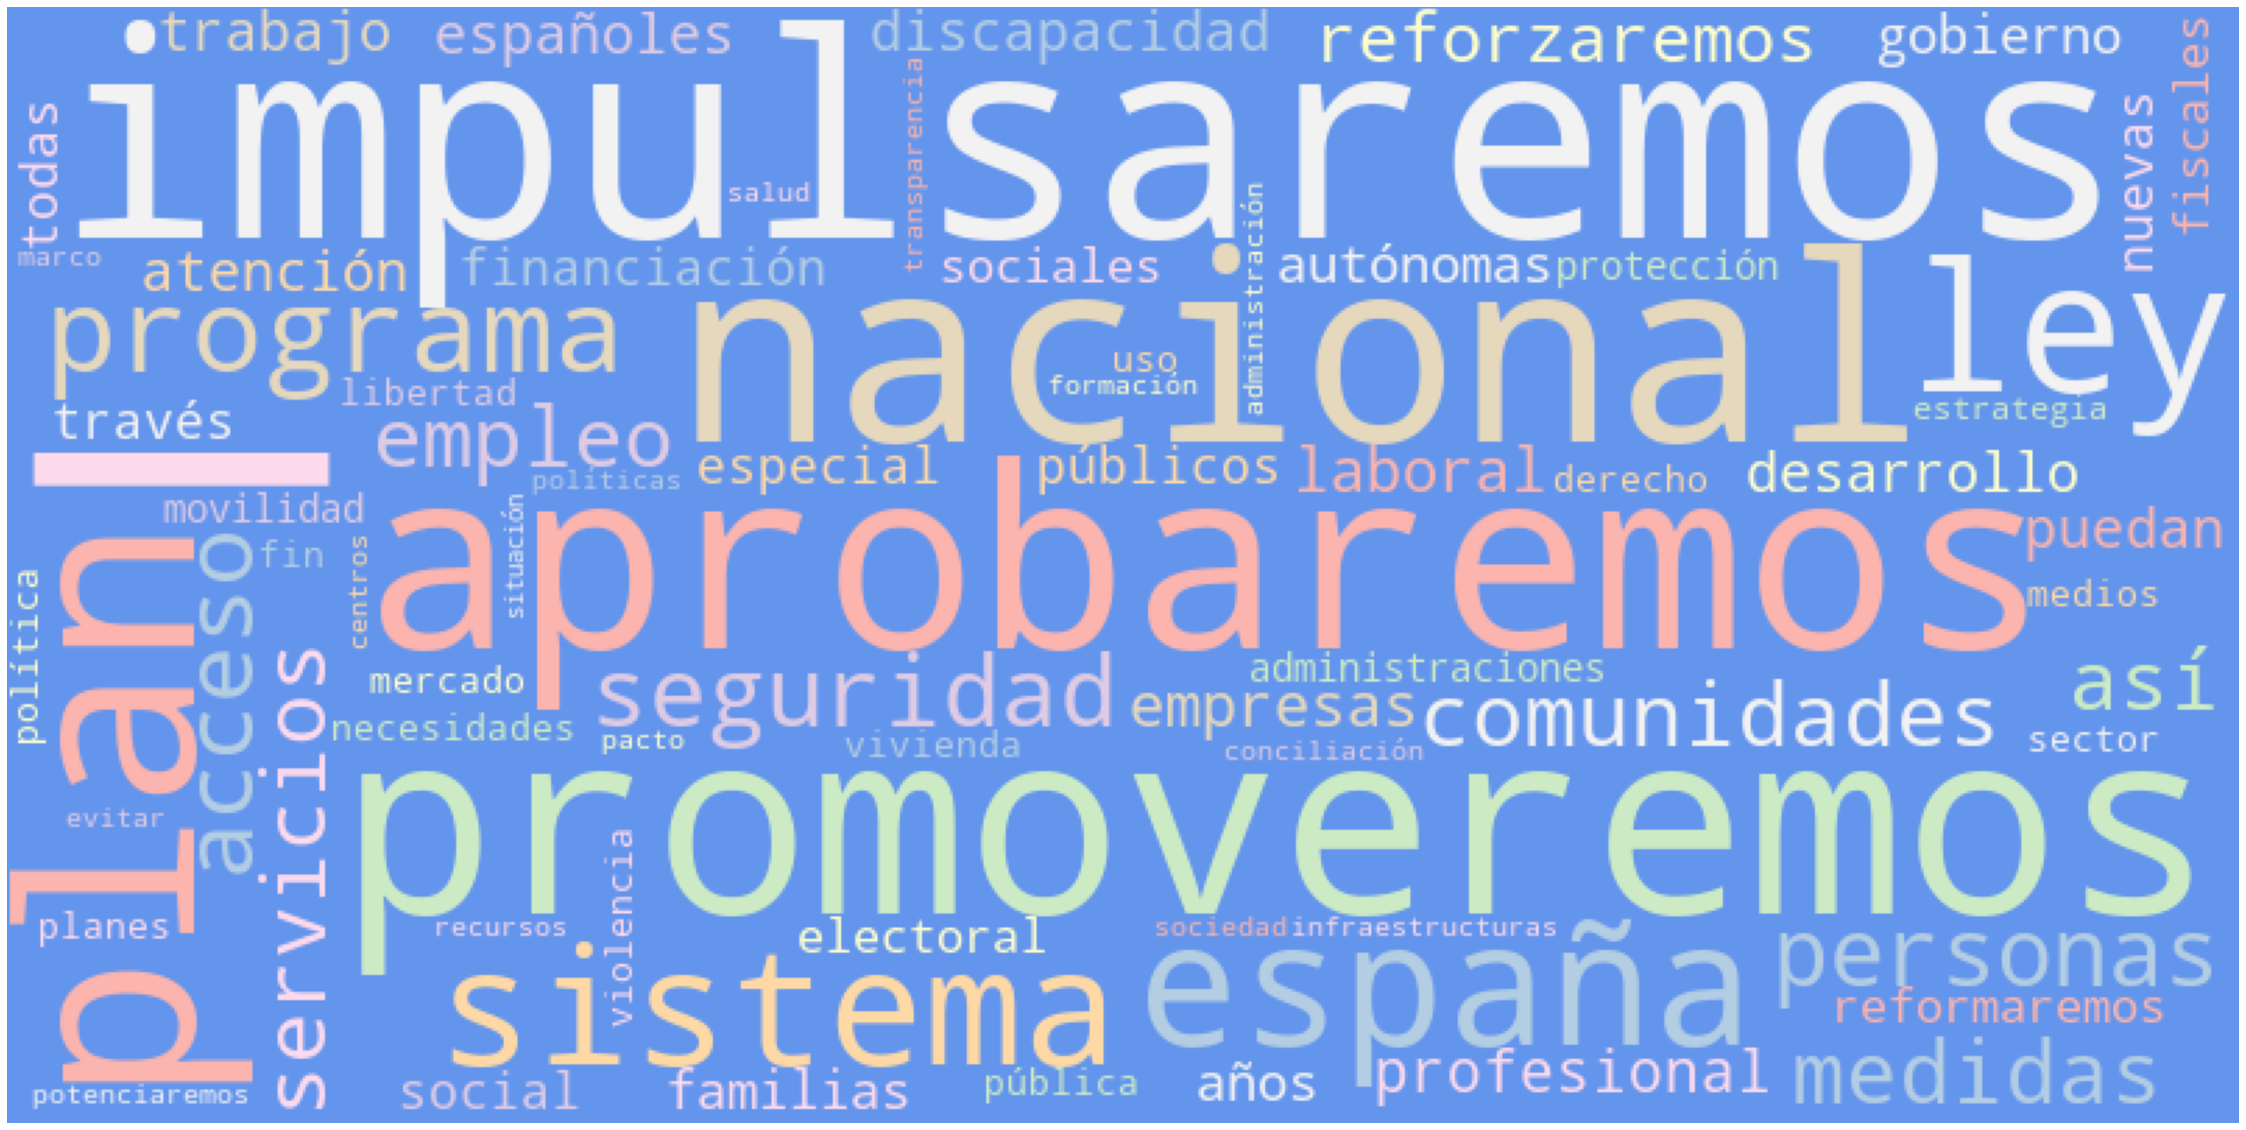

In [234]:
# PP
wordcloud = WordCloud(width = 800, height = 400, random_state=1, background_color='cornflowerblue', max_words=75, 
                      colormap='Pastel1', ranks_only=True, collocations=True, stopwords = STOPWORDS, 
                      normalize_plurals=True, min_word_length=3).generate_from_frequencies(freq_pp)
# Plot
plot_cloud(wordcloud)

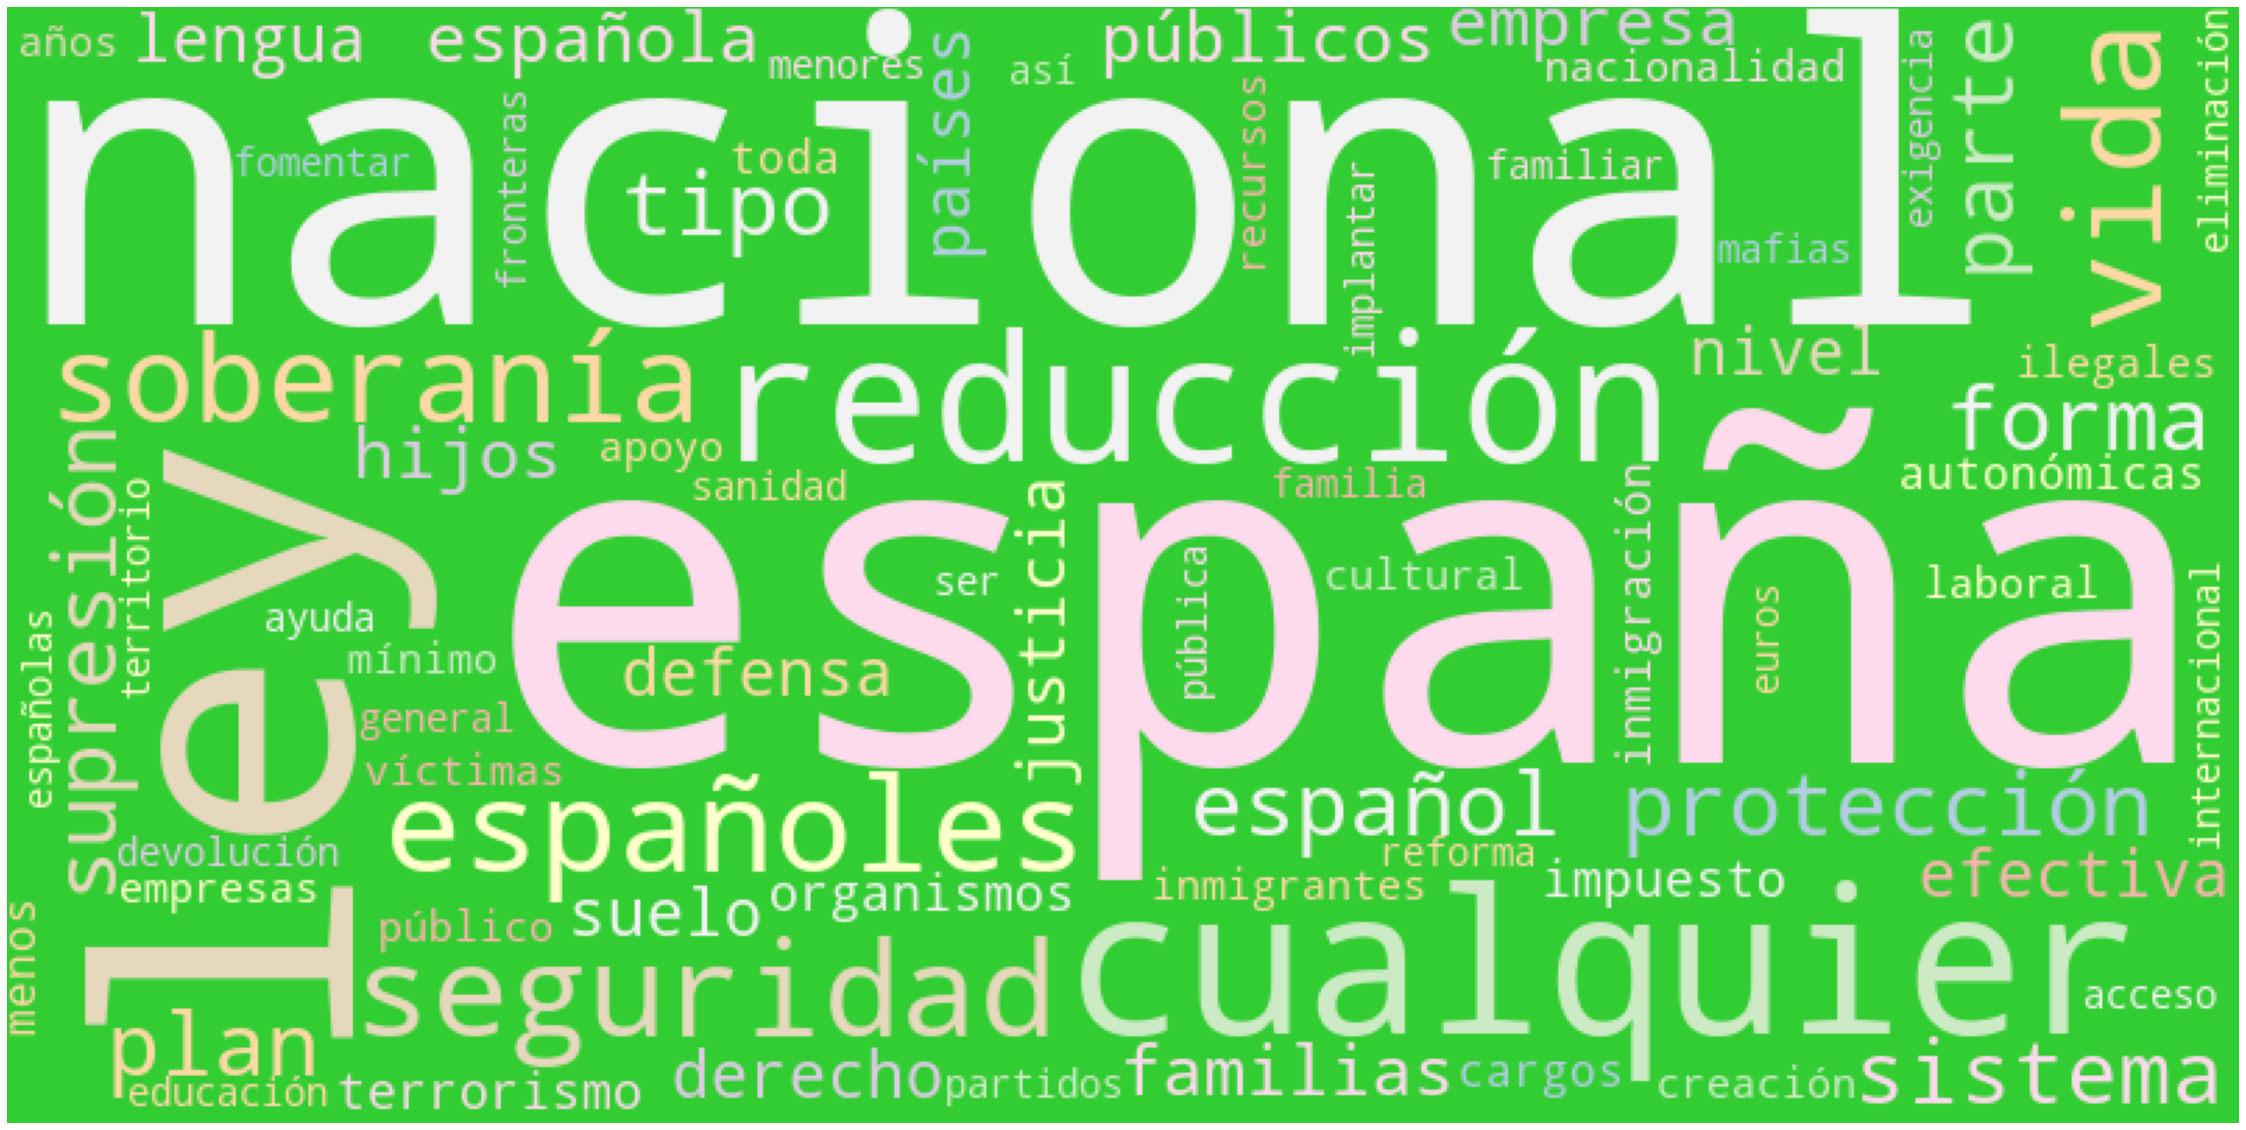

In [239]:
# Vox
wordcloud = WordCloud(width = 800, height = 400, random_state=1, background_color='limegreen', max_words=75, 
                      colormap='Pastel1', ranks_only=True, collocations=True, stopwords = STOPWORDS, 
                      normalize_plurals=True, min_word_length=3).generate_from_frequencies(freq_vox)
# Plot
plot_cloud(wordcloud)